In [173]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,target,SampleID
0,7,184,84,33,0,35.5,0.355,41,1,210
1,6,85,78,0,0,31.2,0.382,42,0,177
2,2,106,64,35,119,30.5,1.400,34,0,148
3,2,100,54,28,105,37.8,0.498,24,0,455
4,5,104,74,0,0,28.8,0.153,48,0,637


In [174]:
df_train.isna().sum()

pregnancies                   0
glucose                       0
blood_pressure                0
skin_thickness                0
insulin                       0
bmi                           0
diabetes_pedigree_function    0
age                           0
target                        0
SampleID                      0
dtype: int64

In [175]:
df_train.columns

Index(['pregnancies', 'glucose', 'blood_pressure', 'skin_thickness', 'insulin',
       'bmi', 'diabetes_pedigree_function', 'age', 'target', 'SampleID'],
      dtype='object')

In [176]:
import numpy as np

features = ['pregnancies', 'glucose', 'blood_pressure', 'skin_thickness', 'insulin',
       'bmi', 'diabetes_pedigree_function', 'age']
target = 'target'

X = df_train[features]
y = df_train[target]

X_final = df_test[features]

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=features)
X_final = pd.DataFrame(scaler.transform(X_final), columns=features)

X.head()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age
0,0.8,1.595238,0.666667,0.31250,-0.292308,0.356322,-0.075188,0.647059
1,0.6,-0.761905,0.333333,-0.71875,-0.292308,-0.137931,-0.007519,0.705882
2,-0.2,-0.261905,-0.444444,0.37500,0.623077,-0.218391,2.543860,0.235294
3,-0.2,-0.404762,-1.000000,0.15625,0.515385,0.620690,0.283208,-0.352941
4,0.4,-0.309524,0.111111,-0.71875,-0.292308,-0.413793,-0.581454,1.058824


In [177]:
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score

model = LinearSVC(random_state=42, class_weight='balanced')

cross_val_score(model, X, y, cv=5, scoring='f1')

array([0.69565217, 0.66666667, 0.68421053, 0.68421053, 0.62162162])

In [178]:
model.fit(X, y)
y_final = model.predict(X_final)

In [179]:
submission = pd.DataFrame({
    "SampleID": df_test.SampleID,
    "label": y_final
})

submission.head()

,SampleID,label
0,731,0
1,199,0
2,25,1
3,418,1
4,388,1


In [180]:
submission.to_csv("submission.csv", index=False)

In [181]:
#skew
df_train.skew()

pregnancies                   0.872460
glucose                       0.218228
blood_pressure               -1.835227
skin_thickness               -0.074063
insulin                       2.095105
bmi                          -0.486273
diabetes_pedigree_function    1.859768
age                           1.099172
target                        0.638923
SampleID                      0.007244
dtype: float64

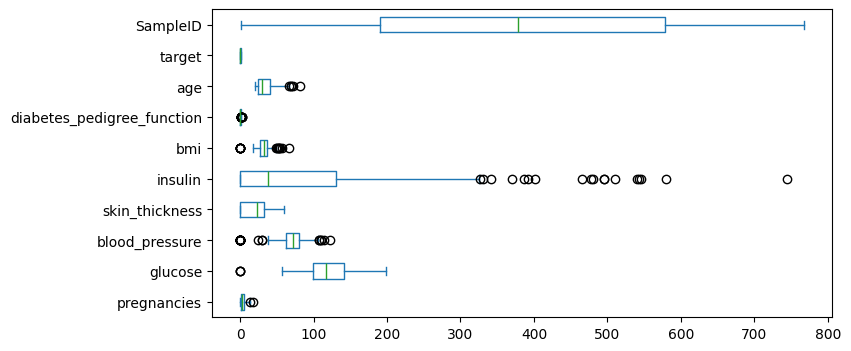

In [182]:
#outliers
import matplotlib.pyplot as plt

df_train.plot(kind='box', figsize=(8,4), vert=False)
plt.show()